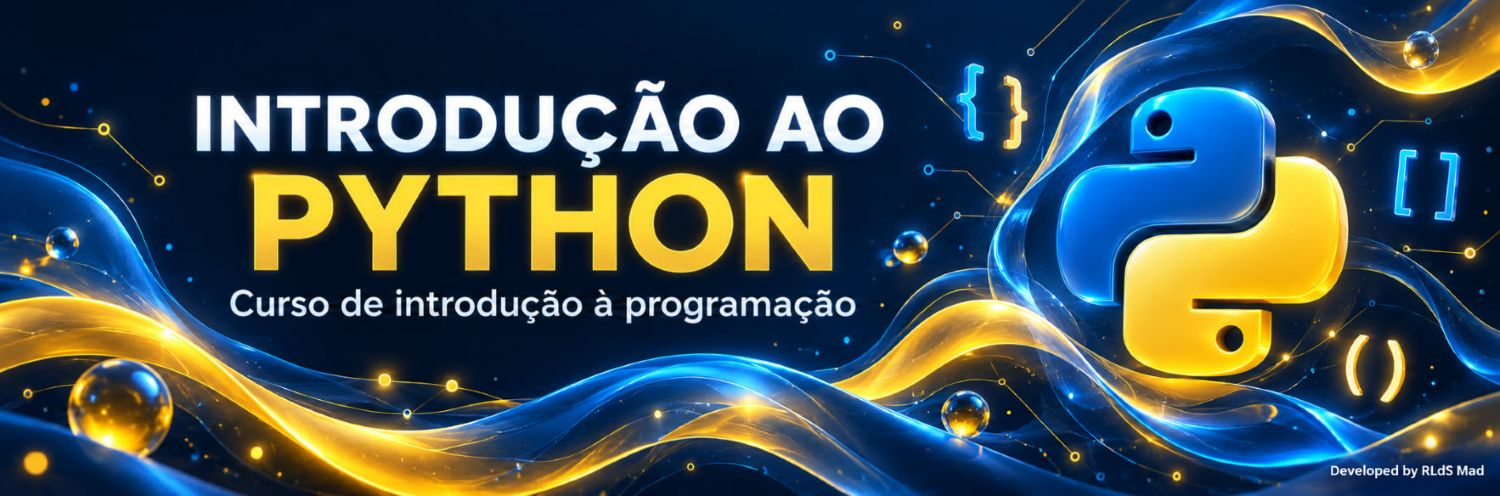

[![Abrir no Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/ricardoluizdasilva/mestrado_ai_estudos/blob/main/Introdu%C3%A7%C3%A3o%20%C3%A0%20Programa%C3%A7%C3%A3o/tutorial_python/nivel_3_ia/N3_15_Arvores_Florestas_Boosting.ipynb)

# Nível IA · Módulo 15 – Árvores de decisão, florestas e *boosting*
## Como uma árvore decide, e porque é que muitas árvores decidem melhor

No N2_04 e no N2_05, as árvores de decisão, a Random Forest e o *boosting* apareceram como estimadores do scikit-learn, comparados com outros numa pesquisa de hiperparâmetros. Este módulo abre a caixa. Constrói-se uma árvore de raiz em NumPy, que dá exatamente o mesmo resultado que o `DecisionTreeClassifier`; vê-se como e porque é que uma árvore sobreajusta e como se poda; e depois juntam-se muitas árvores de duas maneiras opostas: em **paralelo** (*bagging* e Random Forest) e em **sequência** (*boosting*). A última secção mede, com números, a diferença entre as duas: uma reduz sobretudo a **variância**, a outra sobretudo o **viés**.

> **Objetivos:** calcular a impureza de Gini e a entropia e escolher a melhor divisão; construir uma árvore de raiz e lê-la como regras; reconhecer o sobreajuste e podar por custo-complexidade; perceber a instabilidade das árvores; usar árvores de regressão e conhecer os seus limites (previsões em escada, sem extrapolação); explicar o *bagging*, a Random Forest e o erro *out-of-bag*; desconfiar da importância por impureza e usar a importância por permutação; construir *gradient boosting* de raiz e usar o `HistGradientBoostingClassifier` com paragem antecipada; decompor o erro em viés e variância e escolher entre *bagging* e *boosting*; ler uma matriz de confusão e ajustar o limiar de decisão.

**Pré-requisitos:** N2_04 e N2_05 (scikit-learn, validação cruzada, `Pipeline`) e N3_03 (o processo KDD).

| Secção | Tema |
| --- | --- |
| 0. Preparação | bibliotecas e vocabulário |
| 1. Como uma árvore decide | impureza, melhor divisão, uma árvore de raiz |
| 2. Sobreajuste, poda e instabilidade | profundidade, `ccp_alpha`, amostras *bootstrap* |
| 3. Árvores de regressão | escadas e extrapolação |
| 4. *Bagging* e Random Forest | votar entre árvores diferentes |
| 5. Que variáveis importam? | impureza contra permutação |
| 6. *Boosting* | cada árvore corrige as anteriores |
| 7. *Bagging* × *boosting* | viés, variância, número de árvores, ruído, matriz de confusão e limiar |
| 8. Experimenta | três exercícios com solução |

## 0. Preparação

### 0.1 Bibliotecas

Só são precisos NumPy, pandas, Matplotlib e scikit-learn. Todo o módulo corre no CPU em pouco mais de um minuto.

In [1]:
# Executar esta célula

import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from sklearn.datasets import make_friedman1
from sklearn.ensemble import (AdaBoostClassifier, BaggingClassifier, BaggingRegressor, GradientBoostingClassifier,
                              GradientBoostingRegressor, HistGradientBoostingClassifier, RandomForestClassifier,
                              RandomForestRegressor)
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split, validation_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, export_text, plot_tree

plt.rcParams.update({"figure.dpi": 100})
print(f"scikit-learn {sklearn.__version__} | NumPy {np.__version__}")

scikit-learn 1.9.1 | NumPy 2.5.5


### 0.2 Vocabulário

| Termo | Significado |
| --- | --- |
| **Nó**, **folha** | cada pergunta da árvore é um nó; os nós finais, que dão a previsão, são folhas |
| **Impureza** | quão misturadas estão as classes num nó (Gini ou entropia); 0 quando só há uma classe |
| **Profundidade** | o número máximo de perguntas desde a raiz até uma folha |
| **Poda** | cortar ramos de uma árvore grande que não compensam a complexidade que acrescentam |
| **Amostra *bootstrap*** | amostra do mesmo tamanho que os dados, tirada **com reposição** |
| ***Bagging*** | *bootstrap aggregating*: treinar modelos em amostras *bootstrap* e juntar as previsões |
| **Erro *out-of-bag* (OOB)** | o erro de cada exemplo medido só pelos modelos que não o viram no treino |
| ***Boosting*** | treinar modelos em sequência, cada um focado no que os anteriores erraram |
| **Viés** e **variância** | o erro sistemático de um método e quanto as suas previsões mudam com os dados de treino |

## 1. Como uma árvore decide

### 1.1 Os dados: clientes que cancelam o contrato

Uma operadora de telecomunicações quer saber que clientes vão **cancelar o contrato** no próximo mês, para lhes fazer uma proposta antes. Geramos 2000 clientes com cinco atributos: meses de cliente, mensalidade, chamadas para o suporte no último trimestre, idade e tipo de contrato (mensal, anual ou bienal). A probabilidade de cancelar sobe com o contrato mensal, com três ou mais chamadas para o suporte e com mensalidades altas em clientes recentes, e desce com a antiguidade. A **idade não tem efeito nenhum**: é uma variável irrelevante, de propósito, que vai ser útil na secção 5.

Como os dados são gerados, conhecemos a verdade e podemos gerar mais clientes quando for preciso medir com precisão (secção 7). Separamos 25 % para teste, estratificado, e convertemos o contrato em três colunas 0/1 com `pd.get_dummies`. Ao contrário do kNN e da regressão logística, as árvores **não precisam de normalizar** as variáveis: cada pergunta compara uma variável com um limiar, e mudar a escala muda o limiar, mas não a ordem dos valores nem a árvore.

In [2]:
# Executar esta célula

def gerar_clientes(n, semente=0):
    """Clientes sintéticos e o rótulo 1 = cancelou o contrato."""
    rng = np.random.default_rng(semente)
    meses = rng.integers(1, 73, n)
    mensalidade = np.round(rng.uniform(20, 120, n), 2)
    chamadas = rng.poisson(1.5, n)
    idade = rng.integers(18, 80, n)  # não entra no cálculo da probabilidade
    contrato = rng.choice(["mensal", "anual", "bienal"], n, p=[0.5, 0.3, 0.2])
    z = (-2.5 + 4.0 * (contrato == "mensal") - 2.0 * (contrato == "bienal") + 2.25 * (chamadas >= 3)
         + 3.0 * ((mensalidade > 85) & (meses < 12)) - 0.0625 * meses + 0.025 * (mensalidade - 70))
    cancelou = (rng.random(n) < 1 / (1 + np.exp(-z))).astype(int)
    dados = pd.DataFrame({"meses_cliente": meses, "mensalidade": mensalidade, "chamadas_suporte": chamadas,
                          "idade": idade, "contrato": contrato})
    return dados, cancelou


def preparar(dados):
    return pd.get_dummies(dados, columns=["contrato"], dtype=float)


dados, y = gerar_clientes(2000)
X = preparar(dados)
X_treino, X_teste, y_treino, y_teste = train_test_split(X, y, test_size=0.25, random_state=0, stratify=y)
print(dados.head())
print(f"\nCancelaram: {y.mean():.1%} | treino {len(X_treino)}, teste {len(X_teste)}")
print(f"Referência (prever sempre «não cancela»): exatidão {1 - y_teste.mean():.3f} no teste")

   meses_cliente  mensalidade  chamadas_suporte  idade contrato
0             62        21.30                 0     31   bienal
1             46       102.78                 1     19    anual
2             37        69.62                 1     33    anual
3             20        63.59                 2     53   bienal
4             23        80.18                 0     36    anual

Cancelaram: 23.2% | treino 1500, teste 500
Referência (prever sempre «não cancela»): exatidão 0.768 no teste


### 1.2 Impureza: medir a mistura

Uma árvore faz perguntas do tipo «`meses_cliente` ≤ 11,5?» e separa os clientes em dois grupos. Uma boa pergunta deixa cada grupo o mais **puro** possível: quase só clientes que cancelam, ou quase só clientes que ficam. Com $p_k$ a fração da classe $k$ num nó, as duas medidas habituais são a **impureza de Gini** e a **entropia**:

$$G = 1 - \sum_k p_k^2 \qquad\qquad H = -\sum_k p_k \log_2 p_k$$

As duas valem 0 num nó puro e são máximas com as classes a meias. O Gini é a probabilidade de errar se classificarmos um exemplo ao acaso segundo as proporções do nó; a entropia é a medida de informação do N3_07. Na prática dão árvores muito parecidas; o scikit-learn usa o Gini por omissão.

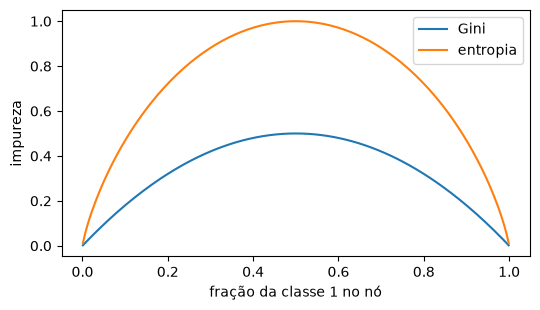

No conjunto de treino: Gini = 0.356, entropia = 0.781


In [3]:
# Executar esta célula

def gini(y):
    p = np.bincount(y, minlength=2) / len(y)
    return 1 - np.sum(p ** 2)


def entropia(y):
    p = np.bincount(y, minlength=2) / len(y)
    p = p[p > 0]
    return -np.sum(p * np.log2(p))


p = np.linspace(0.001, 0.999, 200)
plt.figure(figsize=(5.5, 3.2))
plt.plot(p, 1 - p ** 2 - (1 - p) ** 2, label="Gini")
plt.plot(p, -p * np.log2(p) - (1 - p) * np.log2(1 - p), label="entropia")
plt.xlabel("fração da classe 1 no nó")
plt.ylabel("impureza")
plt.legend()
plt.tight_layout()
plt.show()
print(f"No conjunto de treino: Gini = {gini(y_treino):.3f}, entropia = {entropia(y_treino):.3f}")

### 1.3 A melhor divisão

Para escolher a pergunta, a árvore experimenta **todas**: cada variável e cada limiar possível (o ponto médio entre dois valores consecutivos). Para cada uma, calcula a impureza média dos dois grupos, pesada pelo tamanho de cada um, e fica com a menor:

$$I_{\text{divisão}} = \frac{n_{\text{esq}}}{n}\, I(\text{esq}) + \frac{n_{\text{dir}}}{n}\, I(\text{dir})$$

É uma escolha **gananciosa**: a melhor pergunta agora, sem pensar nas que vêm depois. Encontrar a árvore ótima de um dado tamanho é um problema NP-difícil (Hyafil e Rivest, 1976), por isso todos os algoritmos práticos fazem assim.

In [4]:
# Executar esta célula

def melhor_divisao(X, y, impureza=gini):
    """Devolve (variável, limiar, impureza ponderada) da melhor divisão, ou (None, None, impureza atual)."""
    melhor = (None, None, impureza(y))
    for j in range(X.shape[1]):
        valores = np.unique(X[:, j])
        for a, b in zip(valores[:-1], valores[1:]):
            limiar = (a + b) / 2
            esq = X[:, j] <= limiar
            ponderada = (esq.sum() * impureza(y[esq]) + (~esq).sum() * impureza(y[~esq])) / len(y)
            if ponderada < melhor[2] - 1e-12:
                melhor = (j, limiar, ponderada)
    return melhor


A_treino = X_treino.to_numpy()
inicio = time.time()
j, limiar, imp = melhor_divisao(A_treino, y_treino)
print(f"Melhor primeira pergunta: {X.columns[j]} <= {limiar} | Gini {gini(y_treino):.3f} -> {imp:.3f} "
      f"| {time.time() - inicio:.2f} s")

print("Valores diferentes no treino:", X_treino.nunique().to_dict())
# a melhor divisão de cada variável, para comparar
for k, nome in enumerate(X.columns):
    jj, lim, im = melhor_divisao(A_treino[:, [k]], y_treino)
    print(f"  {nome:18s} melhor limiar {lim if lim is not None else '-':>8} -> Gini {im:.3f}")

Melhor primeira pergunta: contrato_mensal <= 0.5 | Gini 0.356 -> 0.285 | 0.04 s
Valores diferentes no treino: {'meses_cliente': 72, 'mensalidade': 1419, 'chamadas_suporte': 9, 'idade': 62, 'contrato_anual': 2, 'contrato_bienal': 2, 'contrato_mensal': 2}
  meses_cliente      melhor limiar     15.5 -> Gini 0.319


  mensalidade        melhor limiar 94.28999999999999 -> Gini 0.346
  chamadas_suporte   melhor limiar      2.5 -> Gini 0.338
  idade              melhor limiar     77.5 -> Gini 0.356
  contrato_anual     melhor limiar      0.5 -> Gini 0.334
  contrato_bienal    melhor limiar      0.5 -> Gini 0.330
  contrato_mensal    melhor limiar      0.5 -> Gini 0.285


A primeira pergunta escolhida é sobre o contrato: `contrato_mensal <= 0.5` separa os contratos anuais e bienais dos mensais, e baixa o Gini de 0,356 para 0,285. A melhor pergunta sobre a antiguidade (`meses_cliente <= 15.5`) só o baixaria para 0,319, e a melhor sobre a idade, que é irrelevante, praticamente não o muda (0,356). Para chegar aqui, a função experimentou todos os limiares de todas as variáveis; só a mensalidade tem mais de mil valores diferentes no treino. É por isso que as implementações reais ordenam cada variável uma única vez e percorrem os limiares por ordem, ou agrupam os valores em intervalos (secção 6.3).

### 1.4 Uma árvore de raiz

A árvore inteira é a mesma ideia aplicada de forma **recursiva**: divide-se o nó, e repete-se em cada um dos dois grupos, até chegar à profundidade máxima ou a um nó puro. Cada folha guarda a fração de clientes que cancelaram, que é a probabilidade prevista. São cerca de vinte linhas. Comparamos as probabilidades com as do `DecisionTreeClassifier` com a mesma profundidade.

In [5]:
# Executar esta célula

def construir(X, y, profundidade, impureza=gini):
    if profundidade == 0 or len(np.unique(y)) == 1:
        return {"prob": y.mean(), "n": len(y)}
    j, limiar, _ = melhor_divisao(X, y, impureza)
    if j is None:  # nenhuma divisão reduz a impureza
        return {"prob": y.mean(), "n": len(y)}
    esq = X[:, j] <= limiar
    return {"variavel": j, "limiar": limiar,
            "esq": construir(X[esq], y[esq], profundidade - 1, impureza),
            "dir": construir(X[~esq], y[~esq], profundidade - 1, impureza)}


def prever_prob(no, x):
    while "variavel" in no:
        no = no["esq"] if x[no["variavel"]] <= no["limiar"] else no["dir"]
    return no["prob"]


arvore = construir(A_treino, y_treino, profundidade=3)
p_raiz = np.array([prever_prob(arvore, x) for x in X_teste.to_numpy()])
sk = DecisionTreeClassifier(max_depth=3, random_state=0).fit(X_treino, y_treino)
p_sk = sk.predict_proba(X_teste)[:, 1]
print(f"Maior diferença entre as probabilidades: {np.abs(p_raiz - p_sk).max()}")
print(f"Exatidão no teste: de raiz {np.mean((p_raiz > 0.5) == y_teste):.3f} | scikit-learn {sk.score(X_teste, y_teste):.3f}")

Maior diferença entre as probabilidades: 0.0
Exatidão no teste: de raiz 0.802 | scikit-learn 0.802


A maior diferença é exatamente 0: a árvore de raiz encontra as mesmas divisões e as mesmas probabilidades que o `DecisionTreeClassifier`, e as duas acertam em 0,802 dos clientes de teste, contra 0,768 da referência que diz sempre «não cancela». O scikit-learn faz o mesmo cálculo, em C e com estruturas de dados mais eficientes.

### 1.5 Ler a árvore

Uma árvore pequena lê-se como um conjunto de regras. `export_text` imprime-as; com `show_weights=True`, mostra também **quantos** clientes de cada classe chegam a cada folha, o que é essencial para não confiar em folhas com poucos exemplos. `plot_tree` desenha a mesma árvore.

|--- contrato_mensal <= 0.50
|   |--- meses_cliente <= 11.50
|   |   |--- mensalidade <= 80.98
|   |   |   |--- weights: [56.00, 3.00] class: 0
|   |   |--- mensalidade >  80.98
|   |   |   |--- weights: [16.00, 16.00] class: 0
|   |--- meses_cliente >  11.50
|   |   |--- mensalidade <= 103.99
|   |   |   |--- weights: [542.00, 5.00] class: 0
|   |   |--- mensalidade >  103.99
|   |   |   |--- weights: [98.00, 7.00] class: 0
|--- contrato_mensal >  0.50
|   |--- meses_cliente <= 35.50
|   |   |--- mensalidade <= 70.21
|   |   |   |--- weights: [98.00, 104.00] class: 1
|   |   |--- mensalidade >  70.21
|   |   |   |--- weights: [29.00, 129.00] class: 1
|   |--- meses_cliente >  35.50
|   |   |--- chamadas_suporte <= 2.50
|   |   |   |--- weights: [282.00, 43.00] class: 0
|   |   |--- chamadas_suporte >  2.50
|   |   |   |--- weights: [31.00, 41.00] class: 1



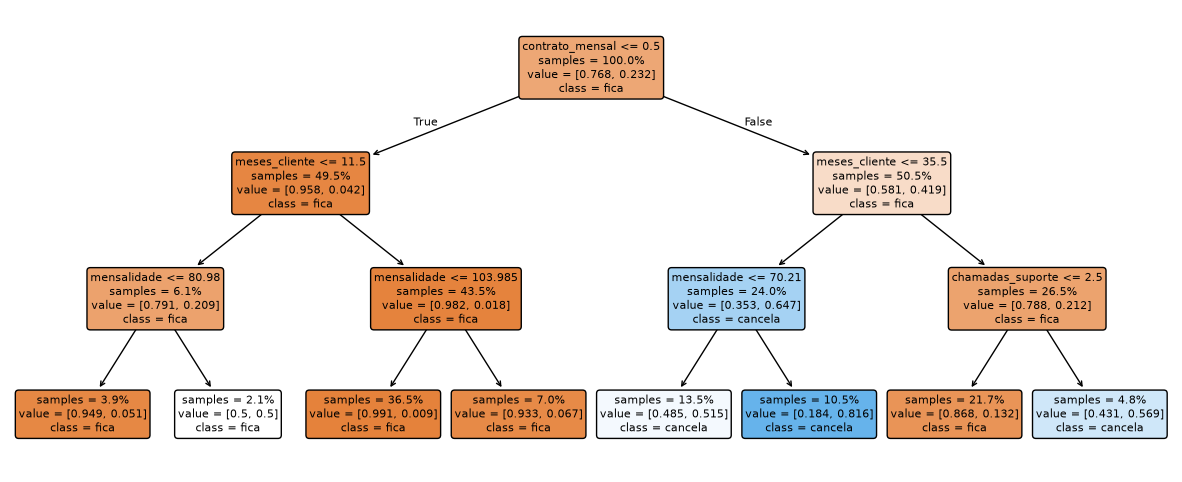

In [6]:
# Executar esta célula

print(export_text(sk, feature_names=list(X.columns), show_weights=True))
plt.figure(figsize=(15, 6))
plot_tree(sk, feature_names=list(X.columns), class_names=["fica", "cancela"], filled=True, rounded=True,
          impurity=False, proportion=True, fontsize=8)
plt.show()

A árvore começa pelo contrato e depois pergunta pela antiguidade, que são as variáveis com mais peso no gerador. Lidas como regras, as folhas dizem, por exemplo:

- **contrato mensal, até 35 meses e mensalidade acima de 70,21 €:** 129 de 158 clientes cancelaram (82 %);
- **contrato mensal, mais de 35 meses e mais de 2 chamadas para o suporte:** 41 de 72 (57 %);
- **contrato mensal, mais de 35 meses e até 2 chamadas:** 43 de 325 (13 %).

Duas coisas para reparar nas contagens. Primeiro, as quatro folhas do ramo dos contratos não mensais preveem todas «fica», com probabilidades muito diferentes: 3 em 59 (5 %) e 16 em 32 (50 %, um empate). A árvore divide para reduzir a impureza, não para mudar a decisão; essas divisões só servem se usarmos as probabilidades, por exemplo com um limiar diferente de 0,5. Segundo, a proporção de uma folha só é fiável se a folha tiver exemplos suficientes; na árvore sem limites da secção seguinte, a maioria das folhas tem cinco clientes ou menos.

## 2. Sobreajuste, poda e instabilidade

### 2.1 A profundidade

Sem limite, a árvore continua a dividir até cada folha ser pura, ou seja, até **memorizar** o treino. Para escolher a profundidade, usamos validação cruzada **só no treino**, como no N2_04: o teste fica guardado para o fim.

                     1      2      3      4      5      6      7      8      9      10     11     12     13     14     15
treino            0.768  0.838  0.847  0.874  0.887  0.906  0.924  0.939  0.954  0.968  0.980  0.988  0.993  0.996  0.999
validação         0.768  0.829  0.829  0.841  0.839  0.836  0.839  0.834  0.823  0.822  0.824  0.816  0.809  0.812  0.807
desvio validação  0.002  0.017  0.008  0.005  0.017  0.024  0.018  0.020  0.017  0.027  0.024  0.020  0.024  0.022  0.023

Árvore sem limites: profundidade 17, 212 folhas, treino 1.000, teste 0.806
Folhas com 1 cliente: 85; com 5 ou menos: 170 de 212
Melhor profundidade em validação cruzada: 4


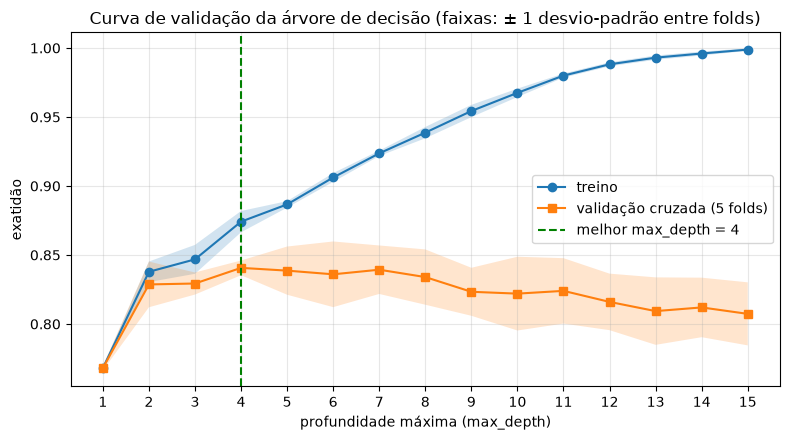

In [7]:
# Executar esta célula

cv = StratifiedKFold(5, shuffle=True, random_state=0)
profundidades = np.arange(1, 16)
treino_cv, valid_cv = validation_curve(DecisionTreeClassifier(random_state=0), X_treino, y_treino,
                                       param_name="max_depth", param_range=profundidades, cv=cv)
curva = pd.DataFrame({"treino": treino_cv.mean(1), "validação": valid_cv.mean(1), "desvio validação": valid_cv.std(1)},
                     index=profundidades)
print(curva.round(3).T.to_string())

completa = DecisionTreeClassifier(random_state=0).fit(X_treino, y_treino)
print(f"\nÁrvore sem limites: profundidade {completa.get_depth()}, {completa.get_n_leaves()} folhas, "
      f"treino {completa.score(X_treino, y_treino):.3f}, teste {completa.score(X_teste, y_teste):.3f}")
folhas = completa.tree_.children_left == -1
tamanhos = completa.tree_.n_node_samples[folhas]
print(f"Folhas com 1 cliente: {np.sum(tamanhos == 1)}; com 5 ou menos: {np.sum(tamanhos <= 5)} de {folhas.sum()}")

melhor_prof = curva["validação"].idxmax()
print(f"Melhor profundidade em validação cruzada: {melhor_prof}")

desvio_treino = treino_cv.std(1)
plt.figure(figsize=(8, 4.5))
plt.plot(profundidades, curva["treino"], "o-", label="treino")
plt.fill_between(profundidades, curva["treino"] - desvio_treino, curva["treino"] + desvio_treino, alpha=0.2)
plt.plot(profundidades, curva["validação"], "s-", label="validação cruzada (5 folds)")
plt.fill_between(profundidades, curva["validação"] - curva["desvio validação"],
                 curva["validação"] + curva["desvio validação"], alpha=0.2)
plt.axvline(melhor_prof, color="green", ls="--", label=f"melhor max_depth = {melhor_prof}")
plt.xticks(profundidades)
plt.grid(alpha=0.3)
plt.xlabel("profundidade máxima (max_depth)")
plt.ylabel("exatidão")
plt.title("Curva de validação da árvore de decisão (faixas: ± 1 desvio-padrão entre folds)")
plt.legend()
plt.tight_layout()
plt.show()

A exatidão no treino sobe sempre, até 0,999 com profundidade 15. A de validação sobe até à profundidade 4 (0,841) e depois desce, até 0,807: a partir daí, as perguntas novas ajustam o ruído do treino. Repara nos desvios-padrão entre *folds* (de 0,005 a 0,027): as profundidades 4 a 7 dão entre 0,836 e 0,841, uma diferença menor do que a variação entre *folds*, por isso estão empatadas.

A árvore sem limites tem 17 níveis e 212 folhas para 1500 clientes, acerta em todos os do treino e em 0,806 dos de teste. Das 212 folhas, 85 têm um só cliente e 170 têm cinco ou menos: é a memorização em estado puro.

### 2.2 Poda por custo-complexidade

Limitar a profundidade corta todos os ramos à mesma altura. A **poda por custo-complexidade** (Breiman et al., 1984) é mais fina: cresce a árvore completa e depois corta, um a um, os ramos que menos reduzem o erro por folha que acrescentam. Com $|T|$ o número de folhas e $R(T)$ a impureza total das folhas, procura-se a árvore que minimiza

$$R_\alpha(T) = R(T) + \alpha\, |T|$$

Com $\alpha = 0$ fica a árvore completa; com $\alpha$ grande, só a raiz. `cost_complexity_pruning_path` devolve os valores de $\alpha$ em que a árvore muda, e escolhemos um por validação cruzada.

92 valores de alpha no caminho; 40 testados
Melhor alpha 0.00297: 12 folhas, profundidade 6, validação 0.852, teste 0.850


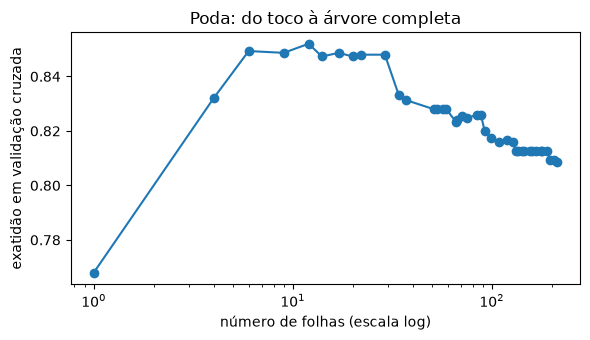

In [8]:
# Executar esta célula

caminho = completa.cost_complexity_pruning_path(X_treino, y_treino)
candidatos = np.unique(np.quantile(caminho.ccp_alphas, np.linspace(0, 1, 40)))
poda = pd.DataFrame([{"alpha": a,
                      "folhas": DecisionTreeClassifier(ccp_alpha=a, random_state=0).fit(X_treino, y_treino).get_n_leaves(),
                      "validação": cross_val_score(DecisionTreeClassifier(ccp_alpha=a, random_state=0),
                                                   X_treino, y_treino, cv=cv).mean()}
                     for a in candidatos])
melhor = poda.loc[poda["validação"].idxmax()]
podada = DecisionTreeClassifier(ccp_alpha=melhor["alpha"], random_state=0).fit(X_treino, y_treino)
print(f"{len(caminho.ccp_alphas)} valores de alpha no caminho; {len(candidatos)} testados")
print(f"Melhor alpha {melhor['alpha']:.5f}: {podada.get_n_leaves()} folhas, profundidade {podada.get_depth()}, "
      f"validação {melhor['validação']:.3f}, teste {podada.score(X_teste, y_teste):.3f}")

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.semilogx(poda["folhas"], poda["validação"], "o-")
ax.set_xlabel("número de folhas (escala log)")
ax.set_ylabel("exatidão em validação cruzada")
ax.set_title("Poda: do toco à árvore completa")
plt.tight_layout()
plt.show()

O caminho tem 92 valores de $\alpha$ e testámos 40. O melhor, $\alpha \approx 0{,}003$, dá uma árvore de 12 folhas e profundidade 6, com 0,852 em validação cruzada, acima da melhor profundidade fixa (0,841), e 0,850 no teste, contra 0,806 da árvore completa. A poda ganha porque não corta tudo à mesma altura: mantém um ramo fundo onde há sinal (por exemplo, nos clientes com contrato mensal) e reduz a um só nó os ramos onde as divisões só ajustavam ruído. No gráfico, à esquerda está o toco (uma folha) e à direita a árvore completa, e a validação tem um máximo largo entre os dois.

### 2.3 Instabilidade

As árvores têm um defeito que vai ser a chave da secção 4: são **instáveis**. Como cada pergunta depende das anteriores, uma pequena mudança nos dados de treino pode mudar uma divisão perto da raiz, e daí para baixo a árvore toda. Para o ver, treinamos cinco árvores sem limites, cada uma numa amostra *bootstrap* diferente do treino (sorteada com reposição, do mesmo tamanho), e comparamos as primeiras perguntas e as previsões no teste.

In [9]:
# Executar esta célula

rng = np.random.default_rng(0)
previsoes, perguntas = [], []
for k in range(5):
    indices = rng.integers(0, len(X_treino), len(X_treino))
    a = DecisionTreeClassifier(random_state=0).fit(X_treino.iloc[indices], y_treino[indices])
    previsoes.append(a.predict(X_teste))
    t = a.tree_
    esq, dir_ = t.children_left[0], t.children_right[0]
    perguntas.append({"raiz": f"{X.columns[t.feature[0]]} <= {t.threshold[0]:.1f}",
                      "à esquerda": f"{X.columns[t.feature[esq]]} <= {t.threshold[esq]:.1f}",
                      "à direita": f"{X.columns[t.feature[dir_]]} <= {t.threshold[dir_]:.1f}",
                      "folhas": a.get_n_leaves()})
print(pd.DataFrame(perguntas).to_string())
P = np.array(previsoes)
discordancia = np.mean([np.mean(P[i] != P[j]) for i in range(5) for j in range(i + 1, 5)])
print(f"\nEm média, duas destas árvores discordam em {discordancia:.1%} dos clientes de teste")

                     raiz             à esquerda                à direita  folhas
0  contrato_mensal <= 0.5  meses_cliente <= 11.5    meses_cliente <= 33.5     142
1  contrato_mensal <= 0.5  meses_cliente <= 11.5    meses_cliente <= 28.5     138
2  contrato_mensal <= 0.5  meses_cliente <= 11.5  chamadas_suporte <= 2.5     138
3  contrato_mensal <= 0.5  meses_cliente <= 10.5    meses_cliente <= 35.5     136
4  contrato_mensal <= 0.5  meses_cliente <= 10.5    meses_cliente <= 42.5     138

Em média, duas destas árvores discordam em 19.1% dos clientes de teste


As cinco árvores começam pela mesma pergunta (o contrato mensal é tão forte que ganha sempre) e a segunda pergunta à esquerda é quase a mesma (meses até 11,5 ou 10,5). À direita, porém, já há quatro perguntas diferentes, e daqui para baixo as árvores, com 136 a 142 folhas, divergem. Em média, duas destas árvores discordam em 19,1 % dos clientes de teste, embora tenham sido treinadas com amostras do **mesmo** conjunto de dados. É a isto que se chama **variância alta**: o modelo depende muito da amostra que lhe calhou.

## 3. Árvores de regressão

Para prever um **número**, a árvore funciona da mesma forma, com duas mudanças: a impureza passa a ser o **erro quadrático** dentro de cada nó (a variância), e cada folha prevê a **média** dos valores que lá chegam. A consequência é que a previsão é uma **função em escada**: constante em cada região.

Usamos 200 pontos de uma curva $y = \sin x + 0{,}1x$ com ruído, para $x$ entre 0 e 10, e comparamos árvores de profundidade 2, 5 e sem limite. Depois pedimos previsões **fora** do intervalo de treino, em $x = 12$ e $x = 15$, e comparamos com uma regressão linear.

max_depth=2      4 folhas | previsão em x=12: 0.70, x=15: 0.70
max_depth=5     31 folhas | previsão em x=12: -0.05, x=15: -0.05
max_depth=None 200 folhas | previsão em x=12: -0.05, x=15: -0.05


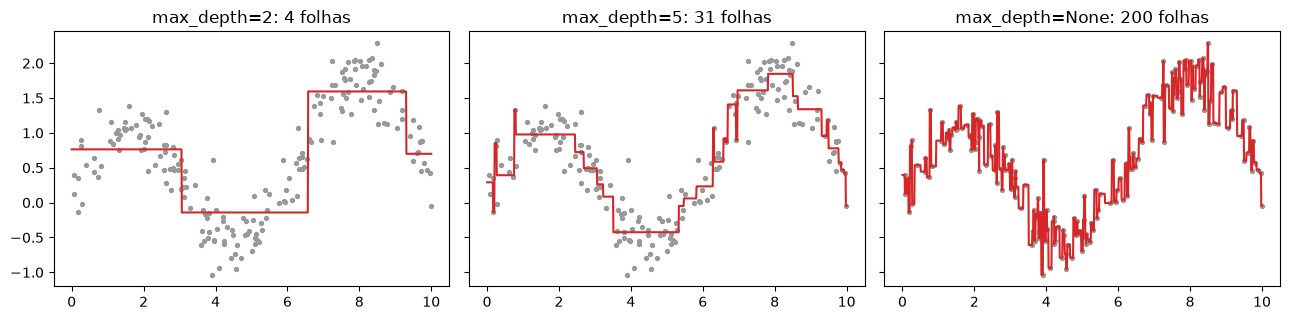

Regressão linear: x=12: 1.39, x=15: 1.71
Valor verdadeiro (sem ruído): x=12: 0.66, x=15: 2.15


In [10]:
# Executar esta célula

rng = np.random.default_rng(1)
x = np.sort(rng.uniform(0, 10, 200))
y_reg = np.sin(x) + 0.1 * x + rng.normal(0, 0.3, 200)
grelha = np.linspace(0, 10, 1000)

fig, eixos = plt.subplots(1, 3, figsize=(13, 3.3), sharey=True)
for eixo, prof in zip(eixos, [2, 5, None]):
    reg = DecisionTreeRegressor(max_depth=prof, random_state=0).fit(x[:, None], y_reg)
    eixo.scatter(x, y_reg, s=8, color="0.6")
    eixo.plot(grelha, reg.predict(grelha[:, None]), color="C3")
    eixo.set_title(f"max_depth={prof}: {reg.get_n_leaves()} folhas")
    previsao_fora = reg.predict([[12], [15]])
    print(f"max_depth={str(prof):4s} {reg.get_n_leaves():3d} folhas | previsão em x=12: {previsao_fora[0]:.2f}, "
          f"x=15: {previsao_fora[1]:.2f}")
plt.tight_layout()
plt.show()

linear = LinearRegression().fit(x[:, None], y_reg)
print(f"Regressão linear: x=12: {linear.predict([[12]])[0]:.2f}, x=15: {linear.predict([[15]])[0]:.2f}")
print(f"Valor verdadeiro (sem ruído): x=12: {np.sin(12) + 1.2:.2f}, x=15: {np.sin(15) + 1.5:.2f}")

Com profundidade 2, a árvore tem 4 folhas e a previsão é uma escada de 4 degraus; com profundidade 5, 31 degraus; sem limite, 200 folhas, uma por ponto, e a previsão segue o ruído. Fora do intervalo de treino, a previsão é **constante**: 0,70 com profundidade 2 e −0,05 com as outras duas, tanto em $x = 12$ como em $x = 15$. É o valor da última folha, a média dos pontos de treino mais à direita. Os valores verdadeiros são 0,66 e 2,15. A regressão linear também erra (1,39 e 1,71), porque a curva não é uma reta, mas pelo menos segue a tendência de subida.

A lição vale para tudo o que se constrói com árvores, incluindo florestas e *boosting*, que são somas de árvores: **não extrapolam**. Se os dados futuros saírem do intervalo do treino (preços que continuam a subir, uma série temporal com tendência), a previsão fica presa no último degrau.

## 4. *Bagging* e Random Forest

### 4.1 *Bagging*: a média de modelos instáveis

A instabilidade da secção 2.3 parece um defeito, mas pode ser aproveitada. Se várias árvores erram em clientes **diferentes**, a votação entre elas erra menos do que cada uma. O ***bagging*** (Breiman, 1996) faz exatamente isso: treina $B$ modelos, cada um numa amostra *bootstrap*, e junta as previsões por votação (classificação) ou média (regressão).

O *bagging* funciona com **qualquer** modelo (`BaggingClassifier`), mas só ajuda se o modelo for instável. Comparamos, com validação cruzada no treino, uma árvore completa e uma regressão logística, sozinhas e com *bagging* de 100 modelos.

In [11]:
# Executar esta célula

inicio = time.time()
linhas = []
for nome, base in [("árvore sem limites", DecisionTreeClassifier(random_state=0)),
                   ("regressão logística", make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000)))]:
    sozinho = cross_val_score(base, X_treino, y_treino, cv=cv).mean()
    bag = cross_val_score(BaggingClassifier(base, n_estimators=100, random_state=0, n_jobs=-1),
                          X_treino, y_treino, cv=cv).mean()
    linhas.append({"modelo": nome, "sozinho": sozinho, "bagging (100)": bag})
print(pd.DataFrame(linhas).set_index("modelo").round(3))
print(f"{time.time() - inicio:.0f} s")

                     sozinho  bagging (100)
modelo                                     
árvore sem limites     0.809          0.859
regressão logística    0.865          0.864
3 s


Com *bagging*, a árvore sem limites passa de 0,809 para 0,859 em validação cruzada; a regressão logística fica igual (0,865 e 0,864). A árvore é instável, e a média de 100 árvores diferentes corrige-lhe a variância; a regressão logística é estável, e 100 cópias quase iguais dão o mesmo que uma.

Repara também que a regressão logística sozinha já é tão boa como a árvore com *bagging*. Não é acaso: o gerador da secção 1.1 é, ele próprio, um modelo logístico, com alguns termos em degrau. Quando um modelo simples corresponde à forma verdadeira dos dados, é difícil batê-lo, e por isso convém ter sempre uma referência simples na comparação.

### 4.2 Random Forest: árvores obrigadas a ser diferentes

O ganho do *bagging* tem um limite. Se houver uma variável muito forte (aqui, o contrato mensal), quase todas as árvores começam por ela e ficam parecidas, e árvores parecidas erram nos mesmos clientes. Para $B$ modelos com variância $\sigma^2$ cada e correlação média $\rho$ entre eles, a variância da média é

$$\text{Var}\left(\frac{1}{B}\sum_{b=1}^{B} f_b\right) = \rho\,\sigma^2 + \frac{1-\rho}{B}\,\sigma^2$$

Com muitas árvores, o segundo termo desaparece, mas o primeiro fica: a correlação $\rho$ é o que limita o ganho. A **Random Forest** (Breiman, 2001) reduz $\rho$ com um truque: em **cada divisão**, a árvore só pode escolher entre um subconjunto sorteado de variáveis, de tamanho `max_features`. Medimos a correlação média entre as probabilidades previstas pelas 300 árvores de cada floresta, no teste.

In [12]:
# Executar esta célula

inicio = time.time()
linhas = []
for mf in [None, "sqrt", 1]:
    rf = RandomForestClassifier(300, max_features=mf, oob_score=True, random_state=0, n_jobs=-1).fit(X_treino, y_treino)
    P = np.array([arv.predict_proba(X_teste.to_numpy())[:, 1] for arv in rf.estimators_])
    C = np.corrcoef(P)
    linhas.append({"max_features": str(mf), "correlação entre árvores": C[np.triu_indices_from(C, 1)].mean(),
                   "OOB": rf.oob_score_, "teste": rf.score(X_teste, y_teste)})
print(pd.DataFrame(linhas).set_index("max_features").round(3))
print(f"{X.shape[1]} variáveis: max_features=None usa todas (é bagging), 'sqrt' sorteia {int(np.sqrt(X.shape[1]))} | "
      f"{time.time() - inicio:.0f} s")

              correlação entre árvores    OOB  teste
max_features                                        
None                             0.498  0.853  0.834
sqrt                             0.455  0.858  0.842
1                                0.415  0.857  0.850
7 variáveis: max_features=None usa todas (é bagging), 'sqrt' sorteia 2 | 2 s


Quanto menos variáveis cada divisão pode escolher, menos parecidas ficam as árvores: a correlação média desce de 0,498 (todas as variáveis, que é o *bagging*) para 0,455 (`sqrt`, 2 das 7) e 0,415 (1 variável ao acaso). A exatidão no teste sobe a acompanhar, de 0,834 para 0,842 e 0,850. O erro OOB, medido em 1500 clientes, quase não muda (de 0,853 a 0,858), e a subida no teste, de 500 clientes, é da ordem do erro-padrão de uma exatidão medida nesse teste (0,016, secção 7.4). A redução da correlação é clara; o ganho de exatidão, aqui, é pequeno. O valor por omissão do scikit-learn para classificação, `sqrt`, é um bom ponto de partida.

### 4.3 Uma floresta de raiz e o erro *out-of-bag*

Uma Random Forest é pouco mais do que um ciclo: sortear uma amostra *bootstrap*, treinar uma árvore com `max_features="sqrt"`, guardar, e no fim fazer a média das probabilidades. De caminho calculamos o erro ***out-of-bag***. Cada amostra *bootstrap* deixa de fora, em média, uma fração $(1 - 1/n)^n \approx e^{-1} \approx 0{,}368$ dos exemplos. Cada exemplo é então avaliado só pelas árvores que **não** o viram, o que dá uma estimativa do erro fora da amostra sem separar dados de validação e sem treinar mais nada.

In [13]:
# Executar esta célula

rng = np.random.default_rng(0)
A_teste = X_teste.to_numpy()
n = len(A_treino)
arvores, soma_oob, conta_oob, fracoes_fora = [], np.zeros(n), np.zeros(n), []
for b in range(200):
    indices = rng.integers(0, n, n)
    fora = np.setdiff1d(np.arange(n), indices)  # os exemplos que esta árvore não viu
    fracoes_fora.append(len(fora) / n)
    arv = DecisionTreeClassifier(max_features="sqrt", random_state=b).fit(A_treino[indices], y_treino[indices])
    arvores.append(arv)
    soma_oob[fora] += arv.predict_proba(A_treino[fora])[:, 1]
    conta_oob[fora] += 1

prob_teste = np.mean([arv.predict_proba(A_teste)[:, 1] for arv in arvores], axis=0)
oob = np.mean(((soma_oob / conta_oob) > 0.5) == y_treino)
individuais = np.array([arv.score(A_teste, y_teste) for arv in arvores])
print(f"Fração média de exemplos fora de cada amostra: {np.mean(fracoes_fora):.3f}")
print(f"Floresta de raiz (200 árvores): teste {np.mean((prob_teste > 0.5) == y_teste):.3f} | OOB {oob:.3f}")
print(f"Árvores sozinhas no teste: média {individuais.mean():.3f}, da pior {individuais.min():.3f} à melhor {individuais.max():.3f}")
for k in (1, 5, 10, 50, 200):
    p = np.mean([arv.predict_proba(A_teste)[:, 1] for arv in arvores[:k]], axis=0)
    print(f"  com {k:3d} árvores: {np.mean((p > 0.5) == y_teste):.3f}")

Fração média de exemplos fora de cada amostra: 0.368
Floresta de raiz (200 árvores): teste 0.852 | OOB 0.859
Árvores sozinhas no teste: média 0.798, da pior 0.744 à melhor 0.834
  com   1 árvores: 0.806
  com   5 árvores: 0.848
  com  10 árvores: 0.844
  com  50 árvores: 0.840
  com 200 árvores: 0.852


Cada amostra *bootstrap* deixou de fora, em média, 0,368 dos clientes, exatamente $e^{-1}$. A floresta de raiz acerta em 0,852 dos clientes de teste, e o erro OOB (0,859) dá uma estimativa parecida sem usar o teste. As árvores sozinhas acertam, em média, em 0,798 (da pior, 0,744, à melhor, 0,834): a floresta é melhor do que **todas** as árvores que a compõem.

O ganho chega cedo: com 5 árvores já são 0,848, e depois a exatidão oscila entre 0,840 e 0,852, a variação normal num teste de 500 clientes. Mais árvores tornam as probabilidades mais estáveis, mas a partir de certo ponto a exatidão deixa de mudar.

## 5. Que variáveis importam?

As florestas dão duas medidas de importância diferentes:

- a **importância por impureza** (`feature_importances_`, também chamada MDI): quanto, em média, as divisões numa variável reduziram a impureza, somado por todas as árvores. É calculada **no treino**, de graça, durante o ajuste;
- a **importância por permutação** (`permutation_importance`): quanto cai a exatidão **no teste** quando se baralham os valores de uma variável, partindo a sua relação com o rótulo.

Para ver a diferença, juntamos aos dados uma coluna `ruido`, com números ao acaso entre 0 e 1, sem relação nenhuma com o cancelamento. Lembra-te de que a `idade` também é irrelevante (secção 1.1).

                  impureza (treino)  permutação (teste)  desvio permutação
meses_cliente                 0.260               0.053              0.013
mensalidade                   0.180               0.026              0.011
ruido                         0.135              -0.022              0.006
contrato_mensal               0.125               0.034              0.007
idade                         0.116              -0.020              0.009
chamadas_suporte              0.095               0.029              0.007
contrato_bienal               0.047               0.004              0.006
contrato_anual                0.041              -0.000              0.005

Valores diferentes no treino: {'meses_cliente': 72, 'mensalidade': 1419, 'chamadas_suporte': 9, 'idade': 62, 'contrato_anual': 2, 'contrato_bienal': 2, 'contrato_mensal': 2, 'ruido': 1500}


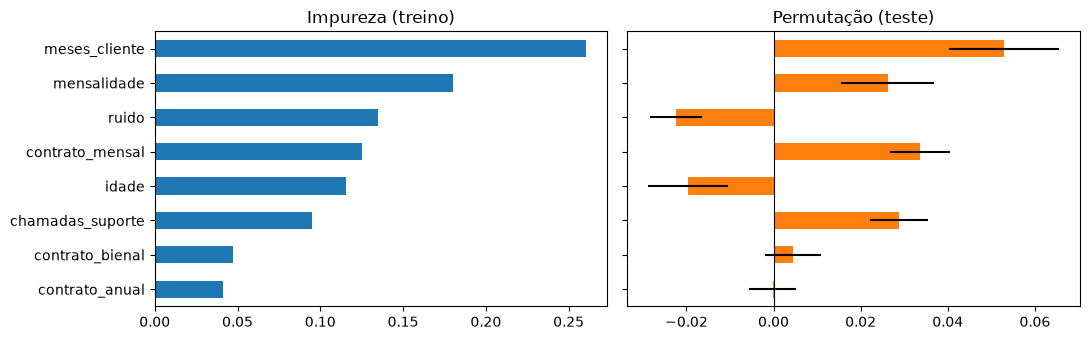

In [14]:
# Executar esta célula

rng = np.random.default_rng(5)
X_treino_r = X_treino.assign(ruido=rng.uniform(0, 1, len(X_treino)))
X_teste_r = X_teste.assign(ruido=rng.uniform(0, 1, len(X_teste)))
rf_r = RandomForestClassifier(300, random_state=0, n_jobs=-1).fit(X_treino_r, y_treino)
perm = permutation_importance(rf_r, X_teste_r, y_teste, n_repeats=10, random_state=0, n_jobs=-1)
importancias = pd.DataFrame({"impureza (treino)": rf_r.feature_importances_,
                             "permutação (teste)": perm.importances_mean,
                             "desvio permutação": perm.importances_std},
                            index=X_treino_r.columns).sort_values("impureza (treino)", ascending=False)
print(importancias.round(3))
print("\nValores diferentes no treino:", X_treino_r.nunique().to_dict())

fig, eixos = plt.subplots(1, 2, figsize=(11, 3.5), sharey=True)
importancias["impureza (treino)"].plot.barh(ax=eixos[0], color="C0", title="Impureza (treino)")
importancias["permutação (teste)"].plot.barh(ax=eixos[1], xerr=importancias["desvio permutação"], color="C1",
                                              title="Permutação (teste)")
eixos[0].invert_yaxis()
eixos[1].axvline(0, color="k", lw=0.8)
plt.tight_layout()
plt.show()

Pela impureza, a coluna `ruido` fica em **terceiro lugar** (0,135), à frente do contrato mensal (0,125), e a idade, também irrelevante, fica à frente das chamadas para o suporte (0,116 contra 0,095). Pela permutação, as duas ficam abaixo de zero (−0,022 e −0,020): baralhá-las até melhora ligeiramente o modelo, porque as árvores as usavam para memorizar. A ordem pela permutação é a que faz sentido com o gerador: meses de cliente, contrato mensal, chamadas e mensalidade.

Há duas razões para o enviesamento (Strobl et al., 2007). A importância por impureza é medida **no treino**, onde as árvores profundas também dividem para memorizar ruído. E uma variável contínua oferece muitos limiares (a coluna `ruido` tem 1500 valores diferentes, a idade 62, os contratos 2), por isso é muitas vezes a escolhida para essas divisões inúteis.

Na prática, usa a importância por permutação, calculada num conjunto que o modelo não viu. Tem um cuidado próprio: se duas variáveis tiverem a mesma informação, baralhar uma delas pouco muda, porque o modelo usa a outra, e as duas parecem menos importantes do que são.

## 6. *Boosting*

### 6.1 *Gradient boosting* de raiz: cada árvore corrige os resíduos

O *bagging* treina árvores **independentes** e faz a média. O ***boosting*** faz o contrário: treina árvores **pequenas, em sequência**, e cada uma tenta corrigir o erro das anteriores. Na versão mais simples, para regressão com erro quadrático (Friedman, 2001), começa-se com a média, $F_0 = \bar{y}$, e em cada passo:

1. calculam-se os **resíduos** $r_i = y_i - F_{m-1}(x_i)$, o que falta acertar;
2. treina-se uma árvore pequena $h_m$ para prever os resíduos;
3. soma-se uma fração dela ao modelo:

$$F_m(x) = F_{m-1}(x) + \eta\, h_m(x)$$

A **taxa de aprendizagem** $\eta$ (aqui 0,1) faz com que cada árvore corrija só um pouco, o que obriga a usar mais árvores mas generaliza melhor. O nome vem de os resíduos serem o gradiente (com o sinal trocado) do erro quadrático: o *boosting* é uma descida de gradiente no espaço das funções. Usamos os dados da secção 3, árvores de profundidade 2 e 200 passos, e comparamos com o `GradientBoostingRegressor`.

         erro no treino  erro face à curva verdadeira
árvores                                              
1                0.5375                        0.4188
5                0.3088                        0.2182
20               0.0990                        0.0512
50               0.0594                        0.0168
200              0.0334                        0.0208
Maior diferença para o GradientBoostingRegressor: 0.00e+00


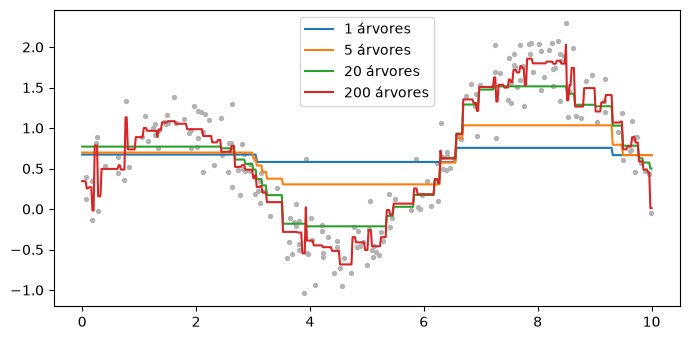

In [15]:
# Executar esta célula

grelha_teste = np.linspace(0, 10, 500)
verdade = np.sin(grelha_teste) + 0.1 * grelha_teste
F = np.full(len(x), y_reg.mean())
F_grelha = np.full(len(grelha_teste), y_reg.mean())
historico, curvas = [], {}
for m in range(1, 201):
    h = DecisionTreeRegressor(max_depth=2, random_state=0).fit(x[:, None], y_reg - F)  # ajusta os resíduos
    F += 0.1 * h.predict(x[:, None])
    F_grelha += 0.1 * h.predict(grelha_teste[:, None])
    if m in (1, 5, 20, 50, 200):
        historico.append({"árvores": m, "erro no treino": np.mean((y_reg - F) ** 2),
                          "erro face à curva verdadeira": np.mean((verdade - F_grelha) ** 2)})
        curvas[m] = F_grelha.copy()
print(pd.DataFrame(historico).set_index("árvores").round(4))

gbr = GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, max_depth=2, random_state=0).fit(x[:, None], y_reg)
print(f"Maior diferença para o GradientBoostingRegressor: {np.abs(gbr.predict(grelha_teste[:, None]) - F_grelha).max():.2e}")

plt.figure(figsize=(7, 3.5))
plt.scatter(x, y_reg, s=8, color="0.7")
for m in (1, 5, 20, 200):
    plt.plot(grelha_teste, curvas[m], label=f"{m} árvores")
plt.legend()
plt.tight_layout()
plt.show()

O erro no treino desce sempre, de 0,5375 para 0,0334. O erro face à curva verdadeira desce até 0,0168 com 50 árvores e **volta a subir**, para 0,0208 com 200: as últimas árvores já estão a ajustar o ruído dos 200 pontos. É o sobreajuste do *boosting*, que a secção 6.3 resolve com paragem antecipada.

A diferença para o `GradientBoostingRegressor` é 0: com erro quadrático, a implementação do scikit-learn é exatamente este ciclo. No gráfico, uma árvore mal mexe na média (só soma 10 % de uma árvore de 4 folhas); com 20 já se vê a forma da curva; com 200, a curva segue-a de perto, com alguns degraus a mais.

### 6.2 O antecessor: AdaBoost

O primeiro algoritmo de *boosting* com sucesso prático foi o **AdaBoost** (Freund e Schapire, 1997), para classificação. Em vez de ajustar resíduos, dá **pesos** aos exemplos: depois de cada árvore (normalmente um «toco», com uma só pergunta), aumenta o peso dos exemplos mal classificados, para que a árvore seguinte se concentre neles. A previsão final é uma votação pesada pela qualidade de cada árvore. Mais tarde percebeu-se que o AdaBoost é um caso particular do *gradient boosting*, com uma função de perda exponencial.

In [16]:
# Executar esta célula

ada = AdaBoostClassifier(n_estimators=200, random_state=0).fit(X_treino, y_treino)
print(f"AdaBoost (200 tocos): exatidão no teste {ada.score(X_teste, y_teste):.3f}")

AdaBoost (200 tocos): exatidão no teste 0.860


### 6.3 `HistGradientBoostingClassifier` e paragem antecipada

Para dados tabulares, o estimador recomendado do scikit-learn é o `HistGradientBoostingClassifier`, inspirado no LightGBM (Ke et al., 2017). Agrupa cada variável em até 255 intervalos (histogramas), o que torna o treino muito mais rápido com muitos dados, e aceita valores em falta sem imputação.

A pergunta essencial no *boosting* é **quantas árvores**: cada árvore nova reduz o erro no treino, e a partir de certo ponto começa a ajustar o ruído. A **paragem antecipada** (*early stopping*) separa uma parte do treino para validação e para quando o erro aí deixa de melhorar durante `n_iter_no_change` iterações. Comparamos três taxas de aprendizagem com paragem, e um modelo com 500 árvores sem paragem.

In [17]:
# Executar esta célula

linhas = []
for lr in (0.3, 0.1, 0.03):
    hgb = HistGradientBoostingClassifier(learning_rate=lr, max_iter=1000, early_stopping=True, validation_fraction=0.2,
                                         n_iter_no_change=20, random_state=0).fit(X_treino, y_treino)
    linhas.append({"taxa": lr, "paragem antecipada": "sim", "árvores usadas": hgb.n_iter_, "teste": hgb.score(X_teste, y_teste)})
hgb500 = HistGradientBoostingClassifier(learning_rate=0.1, max_iter=500, early_stopping=False, random_state=0)
hgb500.fit(X_treino, y_treino)
linhas.append({"taxa": 0.1, "paragem antecipada": "não", "árvores usadas": 500, "teste": hgb500.score(X_teste, y_teste)})
print(pd.DataFrame(linhas).round(3).to_string(index=False))

 taxa paragem antecipada  árvores usadas  teste
 0.30                sim              28  0.848
 0.10                sim              44  0.854
 0.03                sim             110  0.852
 0.10                não             500  0.834


Com paragem antecipada, a taxa 0,3 parou ao fim de 28 árvores (0,848 no teste), a taxa 0,1 ao fim de 44 (0,854) e a taxa 0,03 ao fim de 110 (0,852). Uma taxa menor precisa de mais árvores e dá resultados semelhantes ou ligeiramente melhores; em dados grandes, a diferença costuma ser maior. Sem paragem, com 500 árvores, a exatidão desce para 0,834. O AdaBoost da secção 6.2 acertou em 0,860.

## 7. *Bagging* × *boosting*

As duas famílias juntam muitas árvores, mas por razões opostas. Esta secção põe-nas lado a lado e mede as diferenças. Primeiro, o resumo:

| | *Bagging* / Random Forest | *Boosting* |
| --- | --- | --- |
| Árvores | profundas, treinadas **em paralelo** e de forma independente | pequenas, treinadas **em sequência** |
| Cada árvore sozinha | boa, mas instável (variância alta) | fraca, demasiado simples (viés alto) |
| Juntar reduz sobretudo | a **variância** | o **viés** |
| Mais árvores | não piora; o ganho estabiliza | a partir de certo ponto sobreajusta: precisa de paragem antecipada |
| Hiperparâmetros críticos | poucos (`max_features`, tamanho das folhas) | vários (taxa, número de árvores, profundidade) |
| Paralelização | trivial | só dentro de cada árvore |

### 7.1 Viés e variância, medidos

O erro esperado de um método num ponto $x$ decompõe-se em três parcelas:

$$E\left[(y - \hat{f}(x))^2\right] = \underbrace{\left(E[\hat{f}(x)] - f(x)\right)^2}_{\text{viés}^2} + \underbrace{\text{Var}(\hat{f}(x))}_{\text{variância}} + \sigma^2$$

O **viés** é o erro sistemático: quanto a previsão média se afasta da verdade. A **variância** é quanto a previsão muda de um conjunto de treino para outro. $\sigma^2$ é o ruído dos dados, que nenhum método elimina.

Para medir as duas primeiras parcelas é preciso o que na prática nunca se tem: **muitos conjuntos de treino** do mesmo problema e a função verdadeira $f$. Com dados gerados é possível. Usamos o problema de Friedman (1991), uma função não linear de 10 variáveis das quais só 5 contam, com ruído de variância $\sigma^2 = 1$. Treinamos cada método em 30 conjuntos de treino diferentes, de 200 exemplos, e comparamos as previsões em 500 pontos fixos. Demora cerca de 15 segundos.

                         viés²  variância  erro esperado
método                                                  
árvore profunda           3.72       8.92          13.64
árvore rasa (prof. 2)    10.04       4.93          15.97
bagging (100 profundas)   4.00       1.21           6.21
random forest (100)       5.19       0.75           6.94
boosting (300 rasas)      1.45       1.32           3.77
12 s


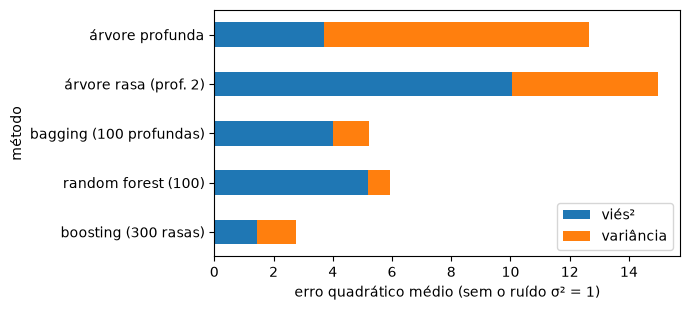

In [18]:
# Executar esta célula

inicio = time.time()
X_pontos, f_pontos = make_friedman1(500, noise=0, random_state=99)  # pontos fixos e o valor verdadeiro f(x)
metodos = {
    "árvore profunda": lambda s: DecisionTreeRegressor(random_state=s),
    "árvore rasa (prof. 2)": lambda s: DecisionTreeRegressor(max_depth=2, random_state=s),
    "bagging (100 profundas)": lambda s: BaggingRegressor(DecisionTreeRegressor(), n_estimators=100, random_state=s, n_jobs=-1),
    "random forest (100)": lambda s: RandomForestRegressor(100, max_features=0.33, random_state=s, n_jobs=-1),
    "boosting (300 rasas)": lambda s: GradientBoostingRegressor(n_estimators=300, max_depth=2, learning_rate=0.1, random_state=s),
}
previsoes = {nome: [] for nome in metodos}
for r in range(30):
    X_r, y_r = make_friedman1(200, noise=1.0, random_state=r)  # um conjunto de treino novo
    for nome, criar in metodos.items():
        previsoes[nome].append(criar(r).fit(X_r, y_r).predict(X_pontos))
linhas = []
for nome, v in previsoes.items():
    v = np.array(v)  # 30 x 500
    vies2 = np.mean((v.mean(axis=0) - f_pontos) ** 2)
    variancia = np.mean(v.var(axis=0))
    linhas.append({"método": nome, "viés²": vies2, "variância": variancia, "erro esperado": vies2 + variancia + 1})
decomposicao = pd.DataFrame(linhas).set_index("método")
print(decomposicao.round(2))
print(f"{time.time() - inicio:.0f} s")

decomposicao[["viés²", "variância"]].plot.barh(stacked=True, figsize=(7, 3.2))
plt.xlabel("erro quadrático médio (sem o ruído σ² = 1)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

Os números confirmam a teoria, com uma surpresa:

- A **árvore profunda** tem viés pequeno (3,72) e variância grande (8,92). O ***bagging*** de 100 árvores profundas mantém o viés (4,00) e corta a variância em 86 %, para 1,21.
- A **Random Forest** corta a variância ainda mais (0,75), mas o viés sobe para 5,19. Com `max_features=0.33`, cada divisão só pode escolher entre 3 das 10 variáveis, das quais metade é irrelevante; muitas divisões são forçadas a usar uma variável fraca. Neste problema, o erro total da floresta (6,94) fica acima do do *bagging* (6,21).
- A **árvore rasa** tem o viés maior (10,04): com 4 folhas, não consegue representar a função. O ***boosting*** de 300 árvores rasas reduz o viés para 1,45, e é o método com menor erro total (3,77).
- A surpresa: a árvore rasa também tem variância alta (4,93), porque os seus poucos limiares mudam muito de amostra para amostra, e o *boosting* reduz também a variância (1,32). Somar muitas árvores, cada uma multiplicada por uma taxa pequena, funciona como uma média.

Em resumo: o *bagging* parte de modelos com pouco viés e muita variância e reduz a variância; o *boosting* parte de modelos com muito viés e reduz o viés.

### 7.2 O número de árvores

Na Random Forest, cada árvore nova é mais uma voz na votação, e a média estabiliza. No *boosting*, cada árvore nova corrige o que falta no **treino**, e depois de corrigir o sinal começa a corrigir o ruído. Para ver as curvas sem a oscilação de um teste de 500 clientes, geramos **10 000 clientes novos** com o mesmo gerador, que servem de conjunto de avaliação grande. Usamos um *gradient boosting* com taxa 0,3 e árvores de profundidade 3, sem paragem, e lemos a exatidão depois de cada árvore com `staged_predict`.

árvores         1      10     30     100    300    1000
boosting       0.754  0.862  0.862  0.854  0.850  0.843
random forest  0.801  0.848  0.852  0.857  0.857  0.858
Boosting: melhor 0.866 com 15 árvores | 4 s


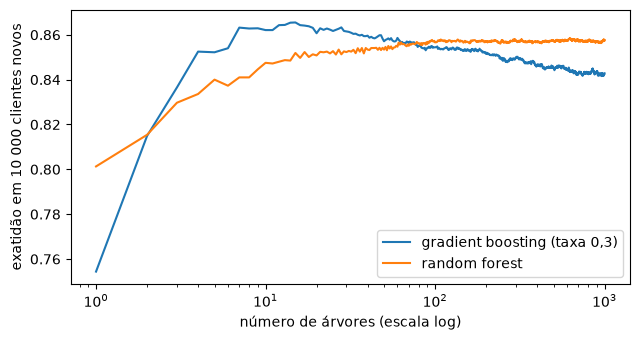

In [19]:
# Executar esta célula

dados_grande, y_grande = gerar_clientes(10000, semente=1)
X_grande = preparar(dados_grande)[X.columns]

inicio = time.time()
gb = GradientBoostingClassifier(n_estimators=1000, learning_rate=0.3, max_depth=3, random_state=0).fit(X_treino, y_treino)
exat_gb = np.array([np.mean(p == y_grande) for p in gb.staged_predict(X_grande)])
rf = RandomForestClassifier(1000, random_state=0, n_jobs=-1).fit(X_treino, y_treino)
P = np.array([arv.predict_proba(X_grande.to_numpy())[:, 1] for arv in rf.estimators_])
exat_rf = np.mean((np.cumsum(P, axis=0) / np.arange(1, 1001)[:, None] > 0.5) == y_grande, axis=1)
marcos = [1, 10, 30, 100, 300, 1000]
print(pd.DataFrame({"boosting": exat_gb[np.array(marcos) - 1], "random forest": exat_rf[np.array(marcos) - 1]},
                   index=pd.Index(marcos, name="árvores")).round(3).T.to_string())
print(f"Boosting: melhor {exat_gb.max():.3f} com {exat_gb.argmax() + 1} árvores | {time.time() - inicio:.0f} s")

plt.figure(figsize=(6.5, 3.5))
plt.semilogx(np.arange(1, 1001), exat_gb, label="gradient boosting (taxa 0,3)")
plt.semilogx(np.arange(1, 1001), exat_rf, label="random forest")
plt.xlabel("número de árvores (escala log)")
plt.ylabel("exatidão em 10 000 clientes novos")
plt.legend()
plt.tight_layout()
plt.show()

O *boosting* começa em 0,754 com uma árvore, chega ao máximo de 0,866 com 15 árvores e depois **desce** lentamente, até 0,843 com 1000. A Random Forest começa em 0,801 (uma árvore profunda) e sobe até **estabilizar**: 0,857 com 100 e com 300 árvores, 0,858 com 1000. Numa Random Forest, o número de árvores só tem de ser suficiente; no *boosting*, é um hiperparâmetro a escolher, normalmente por paragem antecipada.

### 7.3 Rótulos errados

Nos dados reais há sempre rótulos errados: um cliente registado como «cancelou» que só mudou de titular, por exemplo. Diz-se muitas vezes que o *boosting* é sensível a este ruído, porque insiste nos exemplos que erra, e que o *bagging* é robusto. Testamos: trocamos 0 %, 10 %, 20 % e 30 % dos rótulos do **treino** e avaliamos nos 10 000 clientes novos, que têm os rótulos certos. Para separar o efeito da família do efeito da complexidade, incluímos a Random Forest com folhas mínimas de 1 (o valor por omissão) e de 20 exemplos, o *gradient boosting* com 300 árvores sem paragem e o `HistGradientBoostingClassifier` com paragem antecipada. Demora cerca de 10 segundos.

In [20]:
# Executar esta célula

inicio = time.time()
modelos_ruido = {
    "RF, folhas ≥ 1": lambda: RandomForestClassifier(300, random_state=0, n_jobs=-1),
    "RF, folhas ≥ 20": lambda: RandomForestClassifier(300, min_samples_leaf=20, random_state=0, n_jobs=-1),
    "boosting, 300 sem paragem": lambda: GradientBoostingClassifier(n_estimators=300, max_depth=3, random_state=0),
    "boosting, paragem antecipada": lambda: HistGradientBoostingClassifier(early_stopping=True, random_state=0),
    "AdaBoost (300 tocos)": lambda: AdaBoostClassifier(n_estimators=300, random_state=0),
    "regressão logística": lambda: make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)),
}
rng = np.random.default_rng(0)
tabela_ruido = {}
for fracao in (0.0, 0.1, 0.2, 0.3):
    y_sujo = y_treino.copy()
    trocar = rng.random(len(y_sujo)) < fracao
    y_sujo[trocar] = 1 - y_sujo[trocar]
    tabela_ruido[f"{fracao:.0%} trocados"] = {nome: criar().fit(X_treino, y_sujo).score(X_grande, y_grande)
                                             for nome, criar in modelos_ruido.items()}
print(pd.DataFrame(tabela_ruido).round(3))
print(f"{time.time() - inicio:.0f} s")

                              0% trocados  10% trocados  20% trocados  \
RF, folhas ≥ 1                      0.857         0.843         0.818   
RF, folhas ≥ 20                     0.857         0.853         0.848   
boosting, 300 sem paragem           0.853         0.836         0.801   
boosting, paragem antecipada        0.860         0.854         0.843   
AdaBoost (300 tocos)                0.858         0.857         0.840   
regressão logística                 0.852         0.851         0.847   

                              30% trocados  
RF, folhas ≥ 1                       0.752  
RF, folhas ≥ 20                      0.840  
boosting, 300 sem paragem            0.744  
boosting, paragem antecipada         0.800  
AdaBoost (300 tocos)                 0.809  
regressão logística                  0.839  
10 s


Sem ruído, todos os modelos ficam entre 0,852 e 0,860. Com 30 % dos rótulos trocados, a separação é clara, mas **não segue a família**:

- A Random Forest com folhas de 1 cliente cai para 0,752, e o *boosting* com 300 árvores sem paragem para 0,744. Os dois têm capacidade para memorizar os rótulos errados, e memorizam.
- A mesma Random Forest com folhas de pelo menos 20 clientes mantém 0,840. O *boosting* com paragem antecipada fica em 0,800, e o AdaBoost, com tocos de uma só pergunta, em 0,809.
- A regressão logística, o modelo mais simples, é o mais robusto (0,839).

A frase feita de que «o *boosting* é sensível ao ruído e o *bagging* é robusto» não se confirma aqui. O que decide a robustez é **controlar a complexidade**, com folhas maiores, paragem antecipada ou modelos mais simples, qualquer que seja a família.

### 7.4 Comparação final e guia de escolha

Por fim, a avaliação que o teste reservado esperou o módulo todo: a árvore podada (secção 2.2), uma Random Forest, um `HistGradientBoostingClassifier` com paragem antecipada e, como referência, a regressão logística. Mostramos o resultado nos 500 clientes de teste e nos 10 000 clientes novos.

In [21]:
# Executar esta célula

finais = {"árvore podada": podada,
          "random forest (300)": RandomForestClassifier(300, random_state=0, n_jobs=-1).fit(X_treino, y_treino),
          "boosting, paragem antecipada": HistGradientBoostingClassifier(early_stopping=True, random_state=0).fit(X_treino, y_treino),
          "regressão logística": make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000)).fit(X_treino, y_treino)}
final = pd.DataFrame({"teste (500)": {n: m.score(X_teste, y_teste) for n, m in finais.items()},
                      "clientes novos (10 000)": {n: m.score(X_grande, y_grande) for n, m in finais.items()}})
print(final.round(3))
print(f"\nReferência «nunca cancela» nos clientes novos: {1 - y_grande.mean():.3f}")
erro_padrao = np.sqrt(0.85 * 0.15 / len(y_teste))
print(f"Erro-padrão de uma exatidão de 0,85 medida em 500 clientes: {erro_padrao:.3f}")

                              teste (500)  clientes novos (10 000)
árvore podada                       0.850                    0.856
random forest (300)                 0.842                    0.857
boosting, paragem antecipada        0.854                    0.860
regressão logística                 0.836                    0.852

Referência «nunca cancela» nos clientes novos: 0.754
Erro-padrão de uma exatidão de 0,85 medida em 500 clientes: 0.016


No teste de 500 clientes, os quatro modelos ficam entre 0,836 e 0,854; nos 10 000 clientes novos, entre 0,852 e 0,860. O erro-padrão de uma exatidão de 0,85 medida em 500 clientes é 0,016, por isso as diferenças no teste são da ordem de um erro-padrão e não permitem declarar um vencedor. Com 10 000 clientes, a medição é muito mais precisa, e mostra que os quatro estão praticamente empatados. A árvore podada, com 12 folhas que se leem como regras, fica a 0,004 do melhor.

### 7.5 Para lá da exatidão: a matriz de confusão

A exatidão trata todos os erros por igual, mas para a operadora não são iguais. Um cliente que ia cancelar e o modelo não assinalou (**falso negativo**) é um cliente perdido; um cliente assinalado que não ia cancelar (**falso positivo**) custa só uma proposta desnecessária. A **matriz de confusão** separa os dois tipos de erro: nas linhas, a classe verdadeira; nas colunas, a prevista. Dela saem as duas medidas habituais para a classe «cancela» (N2_04):

- **precisão:** dos clientes assinalados, que fração ia mesmo cancelar;
- **sensibilidade** (*recall*): dos clientes que iam cancelar, que fração foi assinalada.

Mostramos as matrizes dos quatro modelos no teste de 500 clientes e as duas medidas, mais o F1 (a média harmónica das duas), nos 10 000 clientes novos.

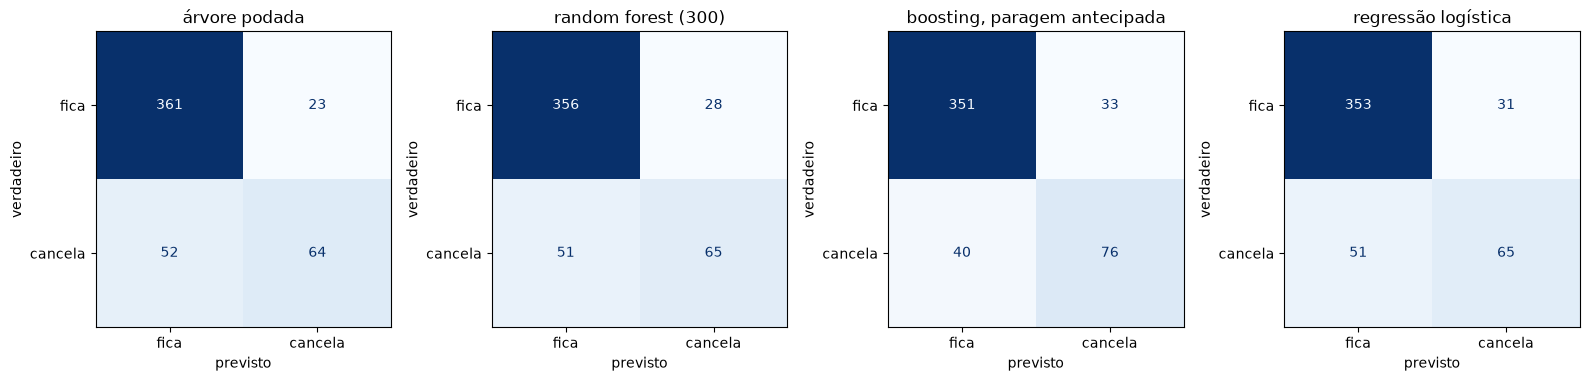

Clientes de teste que cancelaram: 116 de 500
árvore podada                  teste: 64 cancelamentos apanhados, 52 falhados, 23 falsos alarmes
random forest (300)            teste: 65 cancelamentos apanhados, 51 falhados, 28 falsos alarmes
boosting, paragem antecipada   teste: 76 cancelamentos apanhados, 40 falhados, 33 falsos alarmes
regressão logística            teste: 65 cancelamentos apanhados, 51 falhados, 31 falsos alarmes



Classe «cancela», nos 10 000 clientes novos (2456 cancelaram):
                              precisão  sensibilidade     F1
árvore podada                    0.755          0.612  0.676
random forest (300)              0.748          0.632  0.685
boosting, paragem antecipada     0.740          0.659  0.697
regressão logística              0.748          0.602  0.667


In [22]:
# Executar esta célula

fig, eixos = plt.subplots(1, 4, figsize=(16, 3.8))
for eixo, (nome, m) in zip(eixos, finais.items()):
    ConfusionMatrixDisplay.from_estimator(m, X_teste, y_teste, display_labels=["fica", "cancela"], cmap="Blues",
                                          colorbar=False, ax=eixo)
    eixo.set_title(nome)
    eixo.set_xlabel("previsto")
    eixo.set_ylabel("verdadeiro")
plt.tight_layout()
plt.show()

print(f"Clientes de teste que cancelaram: {y_teste.sum()} de {len(y_teste)}")
for nome, m in finais.items():
    vn, fp, fn, vp = confusion_matrix(y_teste, m.predict(X_teste)).ravel()
    print(f"{nome:30s} teste: {vp} cancelamentos apanhados, {fn} falhados, {fp} falsos alarmes")

metricas = pd.DataFrame({nome: {"precisão": precision_score(y_grande, m.predict(X_grande)),
                                "sensibilidade": recall_score(y_grande, m.predict(X_grande)),
                                "F1": f1_score(y_grande, m.predict(X_grande))} for nome, m in finais.items()}).T
print(f"\nClasse «cancela», nos 10 000 clientes novos ({y_grande.sum()} cancelaram):")
print(metricas.round(3))

No teste há 116 clientes que cancelaram, e os quatro modelos falham entre 40 e 52 deles. Com o limiar habitual, **mais de um terço dos cancelamentos passa despercebido**, apesar de uma exatidão de 0,84 a 0,85. O *boosting* é o que apanha mais (76), à custa de mais falsos alarmes (33). Nos 10 000 clientes novos, a precisão dos quatro fica entre 0,740 e 0,755 e a sensibilidade entre 0,602 e 0,659: cerca de três em cada quatro clientes assinalados iam mesmo cancelar, mas só cerca de 60 % dos cancelamentos são assinalados. A exatidão alta deve-se em boa parte à classe maioritária: três em cada quatro clientes ficam (a referência «nunca cancela» acerta em 0,754).

### 7.6 Mudar o limiar de decisão

Todos estes modelos assinalam um cliente quando a probabilidade prevista de cancelar passa de 0,5. Se falhar um cancelamento custar mais do que uma proposta desnecessária, faz sentido **baixar o limiar**: assinalar mais clientes, aceitando mais falsos alarmes para apanhar mais cancelamentos. Com a Random Forest e os 10 000 clientes novos:

In [23]:
# Executar esta célula

prob = finais["random forest (300)"].predict_proba(X_grande)[:, 1]
linhas = []
for limiar in (0.5, 0.4, 0.3, 0.2):
    assinalados = prob > limiar  # o mesmo critério do predict com 0,5
    linhas.append({"limiar": limiar, "assinalados": int(assinalados.sum()),
                   "cancelamentos apanhados": int((assinalados & (y_grande == 1)).sum()),
                   "precisão": precision_score(y_grande, assinalados),
                   "sensibilidade": recall_score(y_grande, assinalados)})
print(pd.DataFrame(linhas).round(3).to_string(index=False))

 limiar  assinalados  cancelamentos apanhados  precisão  sensibilidade
    0.5         2074                     1551     0.748          0.632
    0.4         2538                     1769     0.697          0.720
    0.3         3075                     1980     0.644          0.806
    0.2         3729                     2153     0.577          0.877


Com o limiar 0,5, a floresta assinala 2074 clientes e apanha 1551 dos 2456 cancelamentos (sensibilidade 0,632, precisão 0,748). Com 0,3, assinala 3075 e apanha 1980 (sensibilidade 0,806), com precisão 0,644; com 0,2, apanha 2153 (0,877), mas só 57,7 % dos assinalados iam de facto cancelar. O modelo é o mesmo, só muda a decisão, e é para isto que servem as probabilidades das folhas (secção 1.5).

Não há um limiar «certo»: depende de quanto custa uma proposta e de quanto vale um cliente que fica. Escolhe-se com dados de validação, nunca com o teste, como qualquer outro hiperparâmetro.

**Guia de escolha:**

- **Árvore única, podada:** quando é preciso explicar a decisão regra a regra, ou aplicá-la à mão. Escolhe a poda por validação cruzada e mostra as contagens das folhas.
- **Random Forest:** um bom ponto de partida para dados tabulares. Precisa de pouca afinação (`max_features`, `min_samples_leaf`), mais árvores não fazem mal, dá o erro OOB de graça e paraleliza bem.
- ***Boosting*** (`HistGradientBoostingClassifier`): é muitas vezes o melhor em dados tabulares, sobretudo com muitos dados, mas pede paragem antecipada e alguma afinação da taxa e da profundidade.
- **Sempre:** uma referência simples (aqui, a regressão logística) e um conjunto de avaliação suficientemente grande para que as diferenças signifiquem alguma coisa. E nenhum destes três métodos extrapola para fora do intervalo do treino (secção 3).

## 8. Experimenta

**Exercício 1 – Entropia na árvore de raiz.** A função `construir` aceita o argumento `impureza`. Constrói uma árvore de profundidade 3 com `impureza=entropia`, compara as probabilidades no teste com as do `DecisionTreeClassifier(max_depth=3, criterion="entropy")` e diz se a primeira pergunta muda em relação ao Gini. Que exatidão dá cada critério no teste?

In [24]:
# Escreve aqui o código do exercício 1

<details><summary><b>Ver uma solução possível</b></summary>

```python
arv_h = construir(A_treino, y_treino, profundidade=3, impureza=entropia)
p_h = np.array([prever_prob(arv_h, x) for x in X_teste.to_numpy()])
sk_h = DecisionTreeClassifier(max_depth=3, criterion="entropy", random_state=0).fit(X_treino, y_treino)
print("Maior diferença para o scikit-learn:", np.abs(p_h - sk_h.predict_proba(X_teste)[:, 1]).max())
print("Primeira pergunta:", X.columns[arv_h["variavel"]], "<=", arv_h["limiar"])
print(f"Exatidão: Gini {sk.score(X_teste, y_teste):.3f} | entropia {sk_h.score(X_teste, y_teste):.3f}")
```

A árvore de raiz volta a coincidir com a do scikit-learn. A primeira pergunta é a mesma com os dois critérios (o contrato mensal domina), e na execução de referência a exatidão no teste foi a mesma, 0,802. É o habitual: a escolha entre Gini e entropia raramente pesa tanto como a profundidade ou a poda.

</details>

**Exercício 2 – *Bagging* numa regressão.** Com os dados da secção 3, compara o erro quadrático médio face à curva verdadeira (`verdade`, na `grelha_teste` da secção 6.1) de uma árvore de regressão sem limites e de um `BaggingRegressor` dessa árvore com 1, 10, 50 e 200 estimadores. Desenha a previsão da árvore sozinha e a do *bagging* com 200. O que acontece aos degraus?

In [25]:
# Escreve aqui o código do exercício 2

<details><summary><b>Ver uma solução possível</b></summary>

```python
arv_sozinha = DecisionTreeRegressor(random_state=0).fit(x[:, None], y_reg)
print(f"árvore sozinha: {np.mean((arv_sozinha.predict(grelha_teste[:, None]) - verdade) ** 2):.4f}")
for b in (1, 10, 50, 200):
    bag = BaggingRegressor(DecisionTreeRegressor(), n_estimators=b, random_state=0).fit(x[:, None], y_reg)
    print(f"bagging com {b:3d}: {np.mean((bag.predict(grelha_teste[:, None]) - verdade) ** 2):.4f}")

plt.figure(figsize=(7, 3.5))
plt.scatter(x, y_reg, s=8, color="0.7")
plt.plot(grelha_teste, arv_sozinha.predict(grelha_teste[:, None]), lw=0.8, label="árvore sozinha")
plt.plot(grelha_teste, bag.predict(grelha_teste[:, None]), lw=2, label="bagging (200)")
plt.plot(grelha_teste, verdade, "k--", label="verdade")
plt.legend()
plt.show()
```

A árvore sem limites passa por todos os pontos, ruído incluído, e a sua previsão salta de ponto para ponto. A média de 200 árvores, cada uma treinada numa amostra *bootstrap* diferente, continua a ser uma função em escada, mas com degraus muito mais pequenos e muito menos ruidosa, e o erro face à curva verdadeira desce bastante. Com um só estimador, o *bagging* é só uma árvore treinada numa amostra *bootstrap*: a diferença para a árvore sozinha é obra do acaso, e o ganho real vem de juntar muitas.

</details>

**Exercício 3 – Empates dentro do ruído.** Usa `GridSearchCV` (com o `cv` da secção 2.1) para afinar uma Random Forest de 200 árvores com `max_features` em `[1, 2, 4, None]` e `min_samples_leaf` em `[1, 5, 20]`. Mostra as cinco melhores combinações com a média e o desvio-padrão da validação cruzada. Quantas combinações ficam a menos de um desvio-padrão da melhor? O que concluis sobre a «melhor» combinação?

In [26]:
# Escreve aqui o código do exercício 3

<details><summary><b>Ver uma solução possível</b></summary>

```python
from sklearn.model_selection import GridSearchCV

grelha = GridSearchCV(RandomForestClassifier(200, random_state=0, n_jobs=-1),
                      {"max_features": [1, 2, 4, None], "min_samples_leaf": [1, 5, 20]}, cv=cv)
grelha.fit(X_treino, y_treino)
res = pd.DataFrame(grelha.cv_results_).sort_values("rank_test_score")
print(res[["params", "mean_test_score", "std_test_score"]].head(5).to_string(index=False))
melhor_media, melhor_desvio = res["mean_test_score"].iloc[0], res["std_test_score"].iloc[0]
perto = (res["mean_test_score"] >= melhor_media - melhor_desvio).sum()
print(f"{perto} de {len(res)} combinações a menos de um desvio-padrão da melhor")
```

Na execução de referência, as doze combinações ficaram a menos de um desvio-padrão da melhor: com 1500 clientes de treino e 5 *folds*, as diferenças entre elas são da ordem da variação entre *folds*. A «melhor» combinação é uma entre várias equivalentes; entre combinações empatadas, é razoável preferir a mais simples ou a mais rápida (por exemplo, folhas maiores). E o `best_score_` da melhor é ligeiramente otimista, porque foi escolhida entre doze.

</details>

## Verifica o que aprendeste

1. O que mede a impureza de Gini? Quanto vale num nó com 30 % de uma classe e 70 % da outra?
2. Porque é que a escolha de cada divisão é «gananciosa», e porque é que não se procura a árvore ótima?
3. Porque é que as árvores não precisam de normalizar as variáveis?
4. Porque é que uma árvore sem limites tem exatidão 1 (ou quase) no treino, e o que é que isso diz sobre o teste?
5. Em que difere a poda por custo-complexidade de limitar a profundidade?
6. Porque é que uma folha com 2 exemplos, ambos da mesma classe, não merece confiança?
7. O que acontece quando se pede a uma árvore de regressão uma previsão fora do intervalo de treino?
8. Porque é que o *bagging* ajuda muito uma árvore profunda e quase nada uma regressão logística?
9. O que faz o `max_features` de uma Random Forest, e porque é que isso reduz o erro da média?
10. O que é o erro *out-of-bag*, e porque é que cerca de 37 % dos exemplos ficam fora de cada amostra *bootstrap*?
11. Porque é que a importância por impureza pode dar importância a uma variável de puro ruído?
12. No *gradient boosting*, o que é que cada árvore nova aprende, e para que serve a taxa de aprendizagem?
13. *Bagging* e *boosting*: qual reduz sobretudo a variância e qual o viés? Como se viu isso na secção 7.1?
14. Porque é que mais árvores não prejudicam uma Random Forest, mas podem prejudicar o *boosting*?
15. Na secção 7.5, os modelos têm exatidão de cerca de 0,85 e, no entanto, falham mais de um terço dos cancelamentos. Como é possível, e o que se pode fazer se esses erros forem os mais caros?

<details><summary><b>Ver respostas</b></summary>

1. A probabilidade de errar ao classificar um exemplo do nó ao acaso, segundo as proporções do nó. Com 30 % e 70 %: $1 - 0{,}3^2 - 0{,}7^2 = 0{,}42$.
2. Escolhe a melhor pergunta agora, sem olhar para as seguintes. Encontrar a árvore ótima é um problema NP-difícil; a estratégia gananciosa é rápida e funciona bem na prática.
3. Cada pergunta compara uma variável com um limiar. Mudar a escala muda o limiar, mas não a ordem dos valores, por isso as divisões e a árvore são as mesmas.
4. Porque continua a dividir até cada folha ter uma só classe: memoriza o treino, ruído incluído. Só não chega a 1 se houver exemplos com os mesmos atributos e rótulos diferentes. No teste, o resultado é pior do que o de uma árvore limitada, porque as divisões que só servem para memorizar não generalizam.
5. Limitar a profundidade corta todos os ramos à mesma altura, antes de crescerem. A poda cresce a árvore toda e depois corta os ramos que menos reduzem o erro por folha que acrescentam; pode manter um ramo fundo onde há sinal e cortar um raso onde não há.
6. Porque 2 em 2 (100 %) é compatível com uma probabilidade verdadeira muito diferente; com tão poucos exemplos, a proporção da folha é muito incerta. `show_weights=True` mostra estas contagens.
7. Dá o valor da folha mais próxima, que é a média dos pontos de treino dessa região: uma constante. As árvores não extrapolam tendências.
8. O *bagging* reduz a variância. Uma árvore profunda tem variância alta (secção 2.3), e a média de árvores diferentes corrige-a. A regressão logística é estável: os modelos treinados nas várias amostras *bootstrap* são quase iguais, e a média deles também.
9. Em cada divisão, a árvore só pode escolher entre `max_features` variáveis sorteadas. As árvores ficam mais diferentes umas das outras (correlação $\rho$ menor), e na fórmula da variância da média o termo $\rho\sigma^2$, que não desaparece com mais árvores, diminui.
10. É o erro de cada exemplo calculado só com as árvores que não o usaram no treino; é uma estimativa do erro fora da amostra sem separar dados nem treinar mais. A probabilidade de um exemplo nunca ser sorteado em $n$ tiragens é $(1-1/n)^n$, que tende para $e^{-1} \approx 0{,}368$.
11. Porque é calculada no treino, onde árvores profundas também dividem para memorizar ruído, e porque uma variável contínua oferece muitos limiares possíveis, por isso é muitas vezes escolhida para essas divisões inúteis. A permutação no teste mede só o que a variável ajuda a prever em dados novos.
12. Os resíduos do modelo atual, ou seja, o que ainda falta acertar. A taxa de aprendizagem soma só uma fração de cada árvore, para que nenhuma corrija demasiado; é preciso mais árvores, mas generaliza melhor.
13. O *bagging* reduz a variância: na secção 7.1, de 8,92 (árvore profunda) para 1,21, com o viés quase igual. O *boosting* reduz o viés: de 10,04 (árvore de profundidade 2) para 1,45.
14. Na Random Forest, cada árvore é independente das outras e a média estabiliza; uma árvore a mais não pode piorar muito. No *boosting*, cada árvore ajusta o que falta no treino, e depois de esgotar o sinal começa a ajustar o ruído; por isso se usa paragem antecipada.
15. Três em cada quatro clientes ficam, por isso a exatidão é dominada pela classe maioritária e esconde os erros na classe minoritária. A matriz de confusão separa os falsos negativos dos falsos positivos. Se os falsos negativos forem mais caros, baixa-se o limiar de decisão (secção 7.6), escolhido com dados de validação: apanham-se mais cancelamentos à custa de mais falsos alarmes.

</details>

## Leitura recomendada

- James, G., Witten, D., Hastie, T. e Tibshirani, R. (2021). *[An Introduction to Statistical Learning](https://www.statlearning.com/)*, 2.ª ed. Springer. Capítulo 8 (árvores, *bagging*, florestas e *boosting*). Gratuito, com versão em Python.
- Hastie, T., Tibshirani, R. e Friedman, J. (2009). *[The Elements of Statistical Learning](https://hastie.su.domains/ElemStatLearn/)*, 2.ª ed. Springer. Capítulos 7 (viés e variância), 9.2 (árvores), 10 (*boosting*) e 15 (florestas). Gratuito.
- Breiman, L., Friedman, J., Olshen, R. e Stone, C. (1984). *Classification and Regression Trees*. Wadsworth. O livro do CART, incluindo a poda por custo-complexidade.
- Breiman, L. (1996). [Bagging predictors](https://doi.org/10.1007/BF00058655). *Machine Learning*, 24(2), 123–140.
- Breiman, L. (2001). [Random forests](https://doi.org/10.1023/A:1010933404324). *Machine Learning*, 45(1), 5–32.
- Freund, Y. e Schapire, R. E. (1997). [A decision-theoretic generalization of on-line learning and an application to boosting](https://doi.org/10.1006/jcss.1997.1504). *Journal of Computer and System Sciences*, 55(1), 119–139. O AdaBoost.
- Friedman, J. H. (2001). [Greedy function approximation: A gradient boosting machine](https://doi.org/10.1214/aos/1013203451). *Annals of Statistics*, 29(5), 1189–1232.
- Strobl, C., Boulesteix, A.-L., Zeileis, A. e Hothorn, T. (2007). [Bias in random forest variable importance measures](https://doi.org/10.1186/1471-2105-8-25). *BMC Bioinformatics*, 8, 25. O enviesamento da importância por impureza.
- scikit-learn. [Decision Trees](https://scikit-learn.org/stable/modules/tree.html) e [Ensembles](https://scikit-learn.org/stable/modules/ensemble.html). Guia do utilizador.
- **Módulos relacionados:** N2_04 e N2_05 (scikit-learn, validação e seleção de modelos), N3_03 (processo KDD), N3_07 (entropia e informação).